<a href="https://colab.research.google.com/github/202422/AI-Powered-Academic-Recovery-Dashboard/blob/main/EDA_and_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Packages and dataset loading**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import LabelEncoder

In [ ]:
pd.set_option("display.max_columns", None)

In [ ]:
df = pd.read_csv("/content/data_cleaned.csv")
df

,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,FinalGrade
0,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,6
1,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,6
2,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,10
3,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15
4,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9
353,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,3,16
354,M,21,R,GT3,T,1,1,other,other,course,other,1,1,3,no,no,no,no,no,yes,no,no,5,5,3,3,3,3,3,7
355,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,0,10


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   sex         357 non-null    object
 1   age         357 non-null    int64 
 2   address     357 non-null    object
 3   famsize     357 non-null    object
 4   Pstatus     357 non-null    object
 5   Medu        357 non-null    int64 
 6   Fedu        357 non-null    int64 
 7   Mjob        357 non-null    object
 8   Fjob        357 non-null    object
 9   reason      357 non-null    object
 10  guardian    357 non-null    object
 11  traveltime  357 non-null    int64 
 12  studytime   357 non-null    int64 
 13  failures    357 non-null    int64 
 14  schoolsup   357 non-null    object
 15  famsup      357 non-null    object
 16  paid        357 non-null    object
 17  activities  357 non-null    object
 18  nursery     357 non-null    object
 19  higher      357 non-null    object
 20  internet  

#

# **Exploratory Data Analysis**

In [ ]:
qualitative_features = ["sex", "address", "famsize", "Pstatus", "Mjob", "Fjob", "reason", "guardian", "schoolsup", "famsup", "paid",
                        "activities",	"nursery",	"higher",	"internet",	"romantic"]
quantitative_features = list(df.columns.difference(qualitative_features))

In [ ]:
quantitative_features

['Dalc',
 'Fedu',
 'FinalGrade',
 'Medu',
 'Walc',
 'absences',
 'age',
 'failures',
 'famrel',
 'freetime',
 'goout',
 'health',
 'studytime',
 'traveltime']

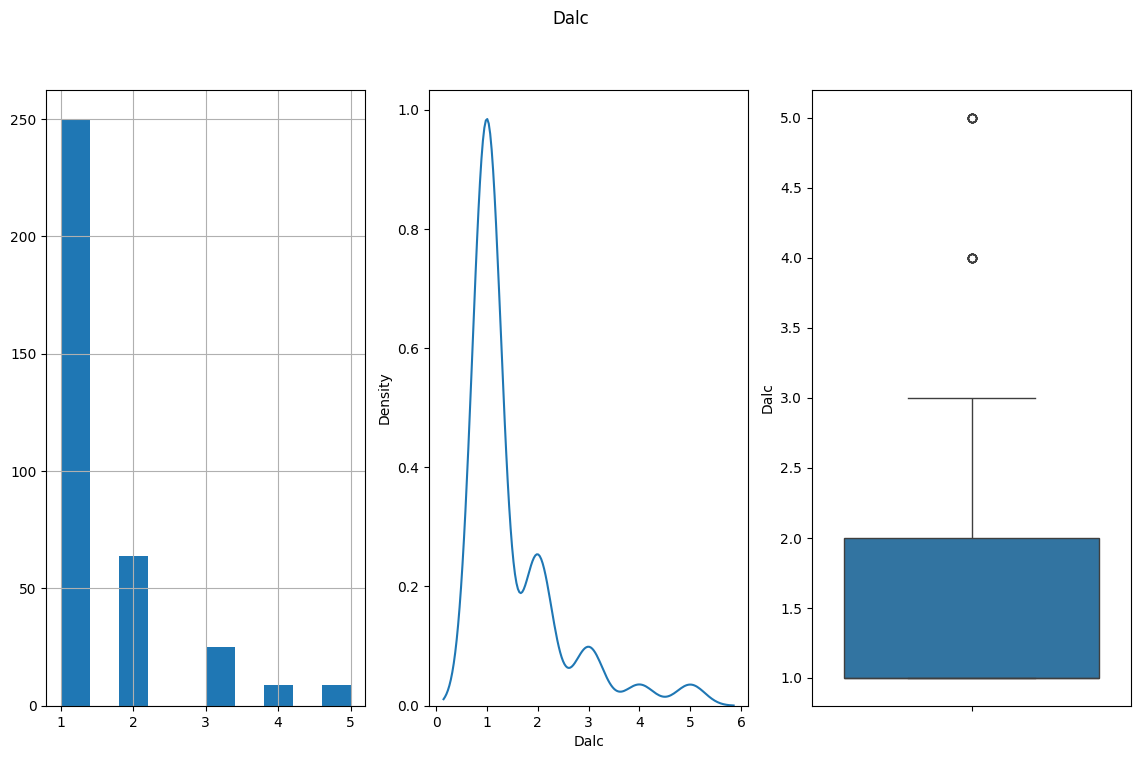

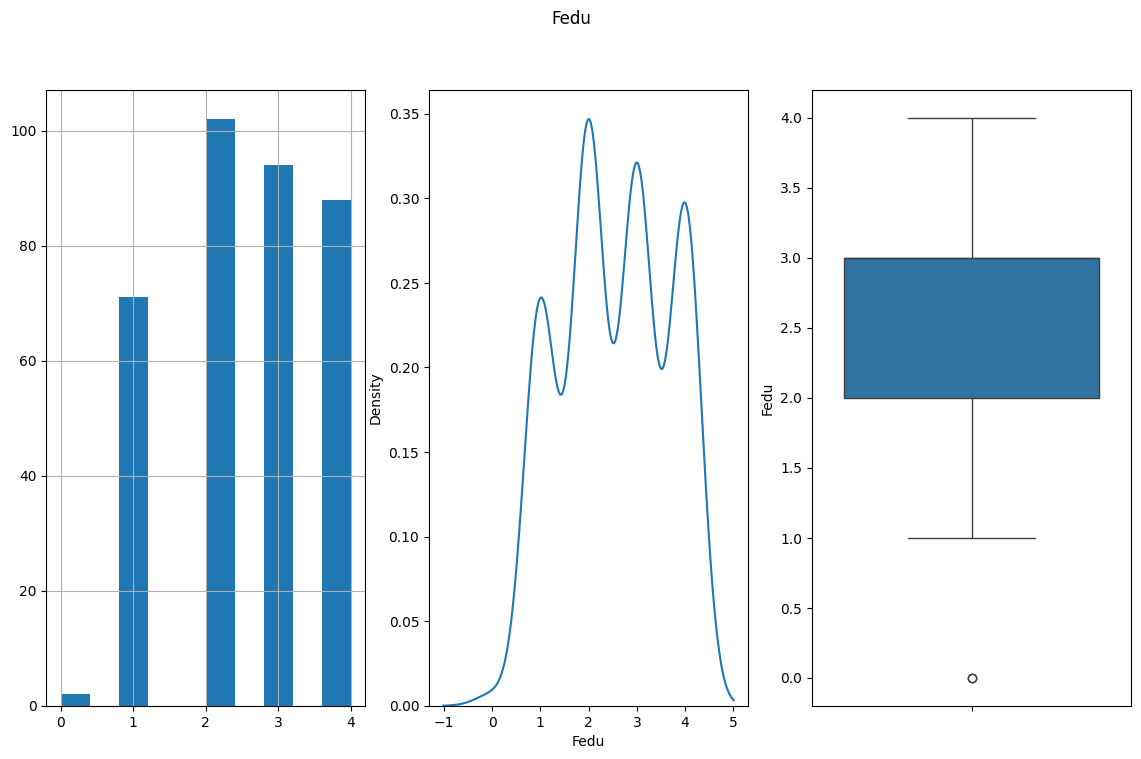

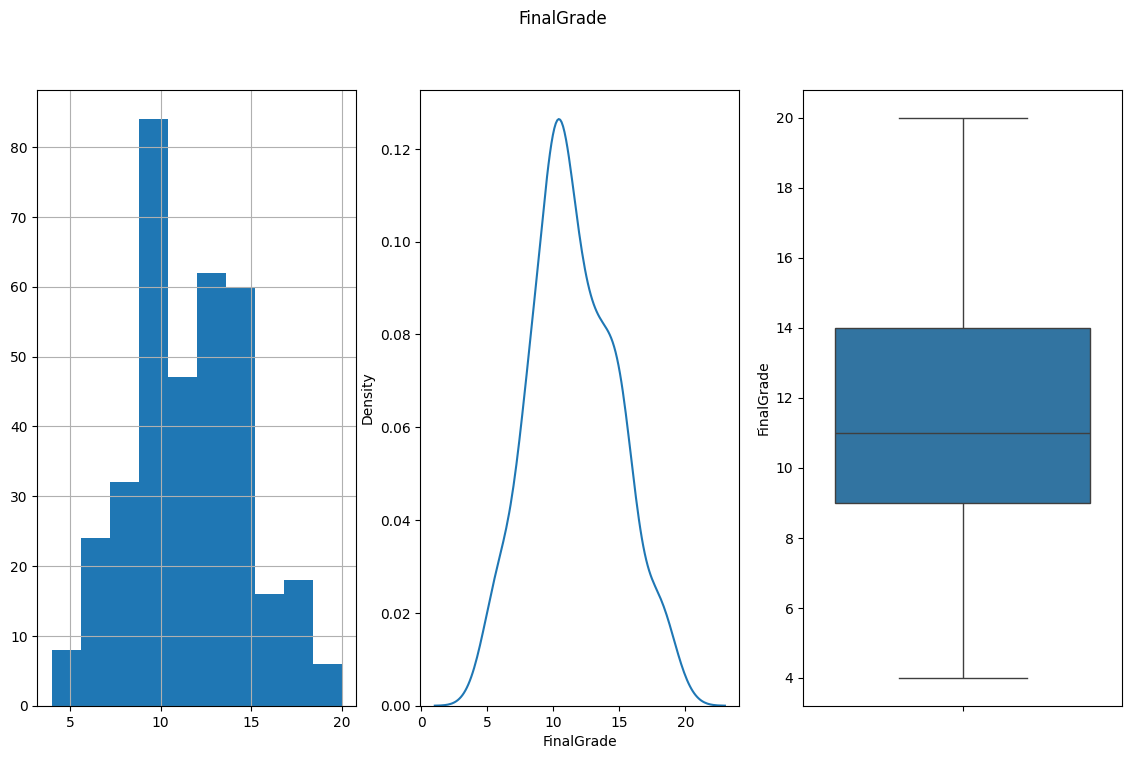

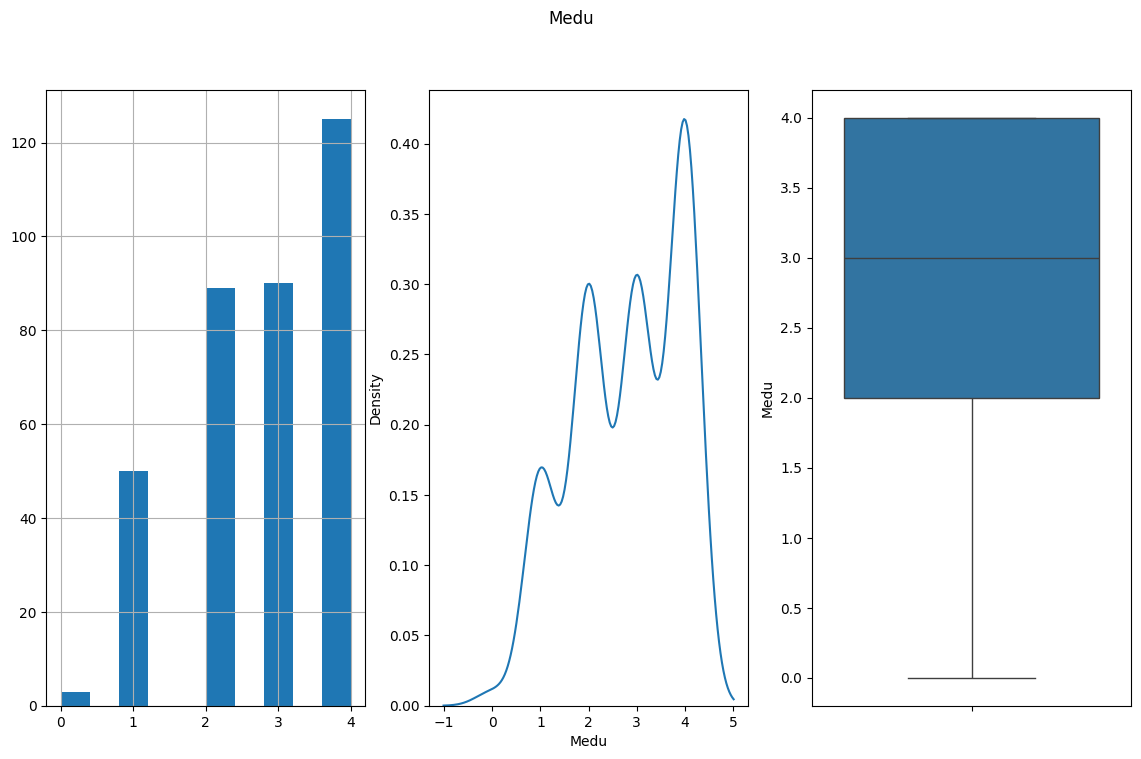

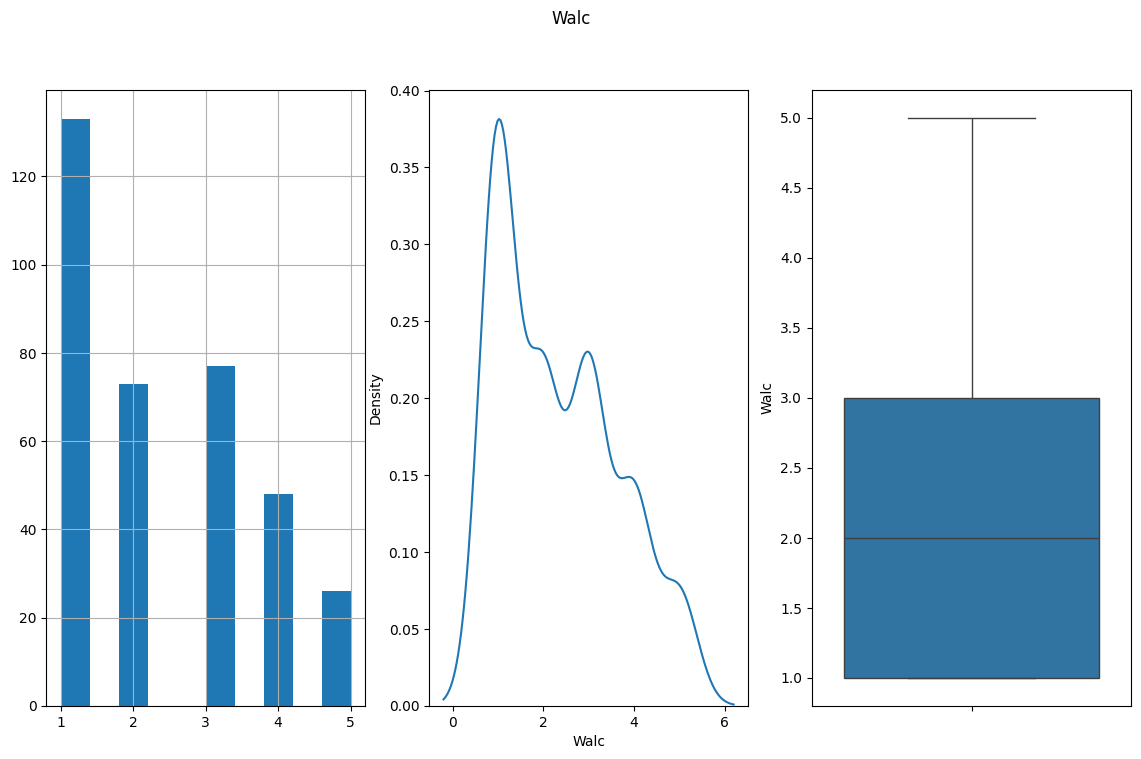

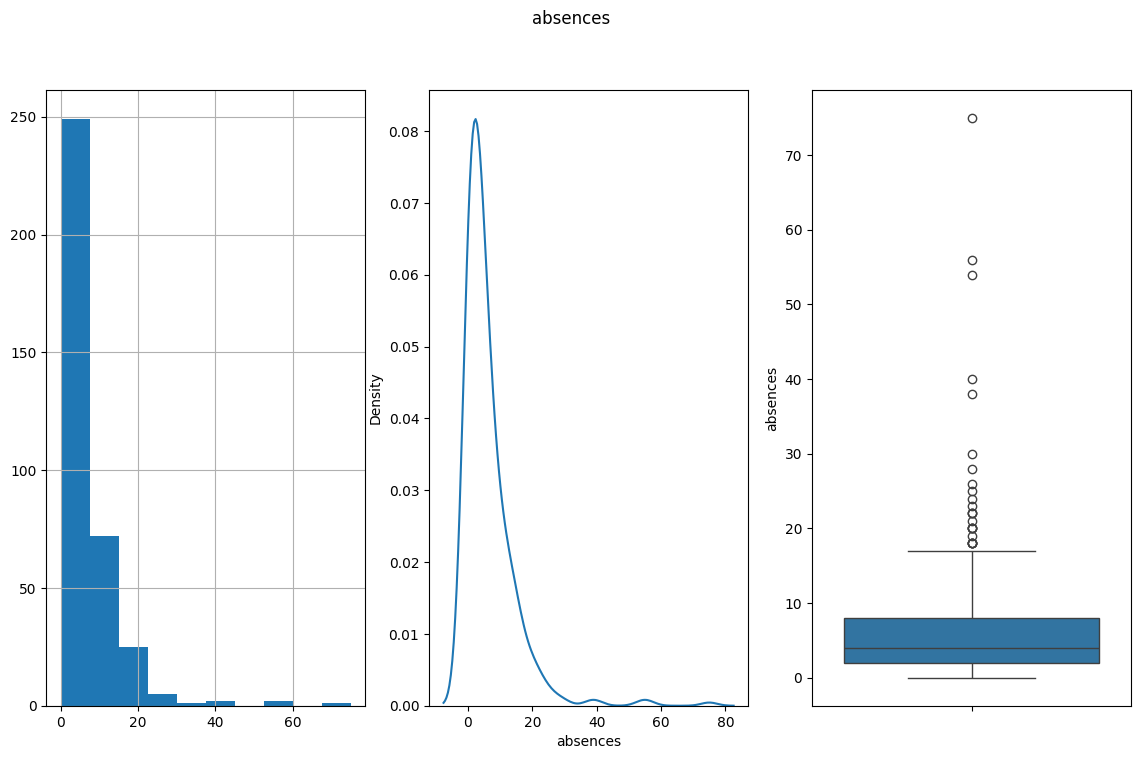

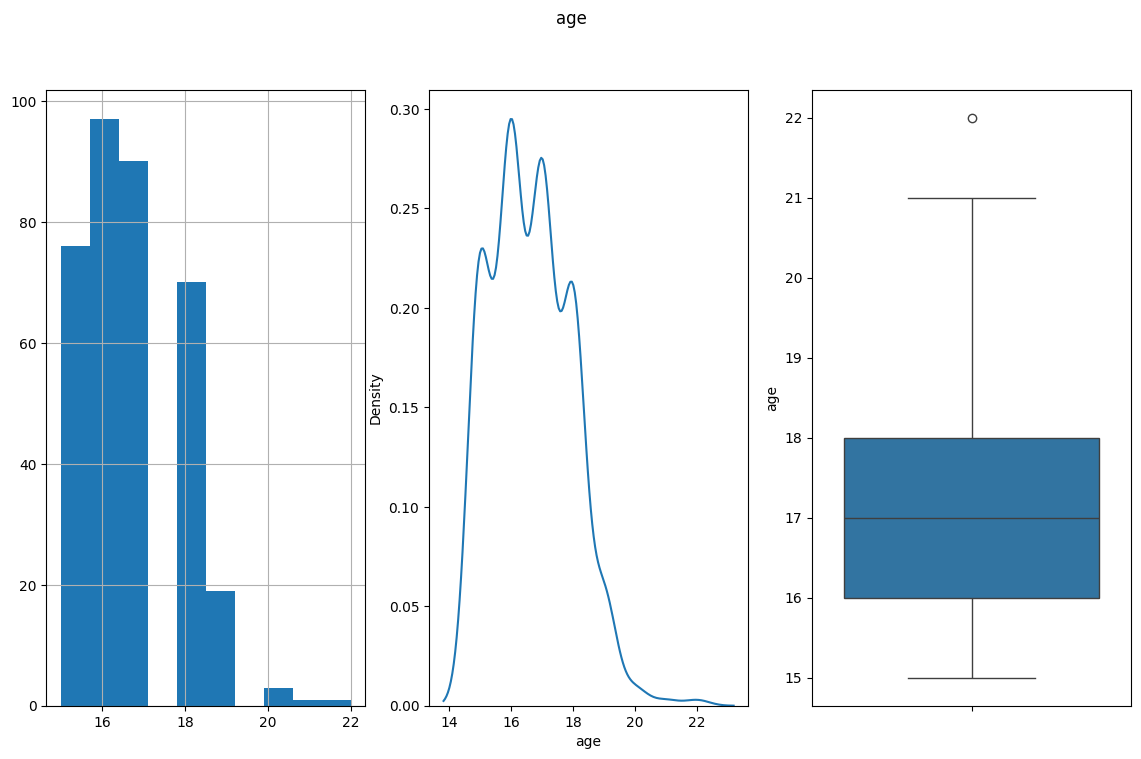

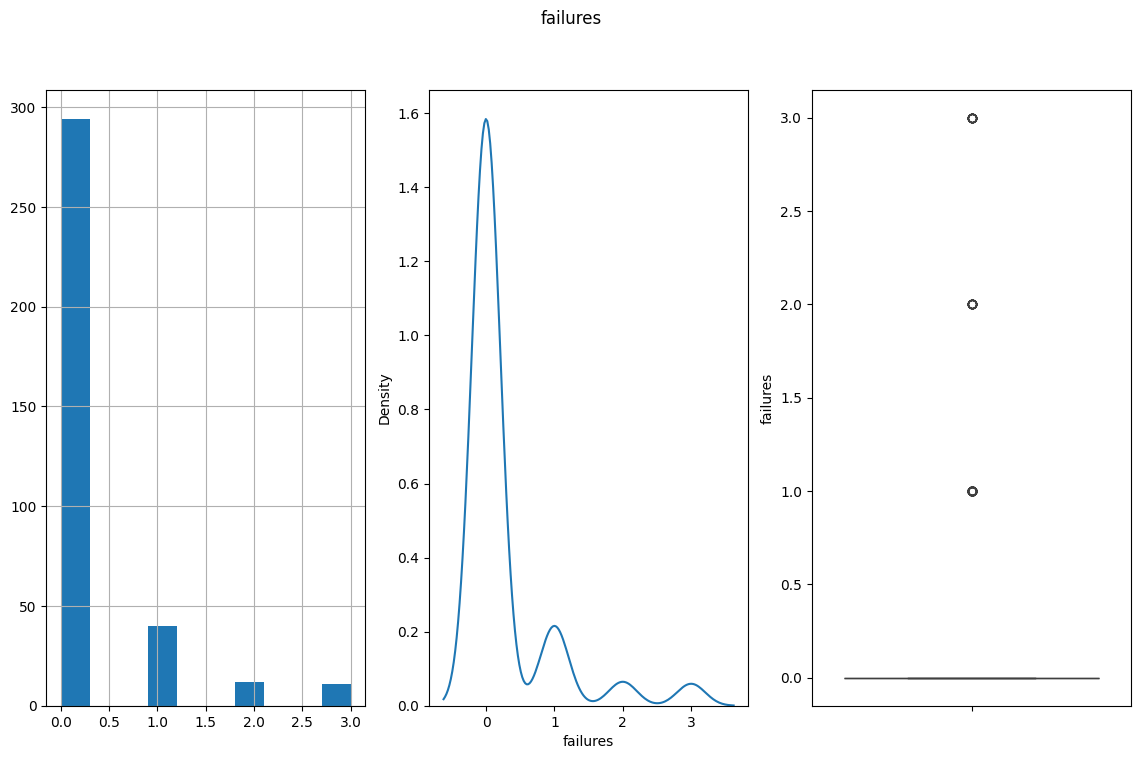

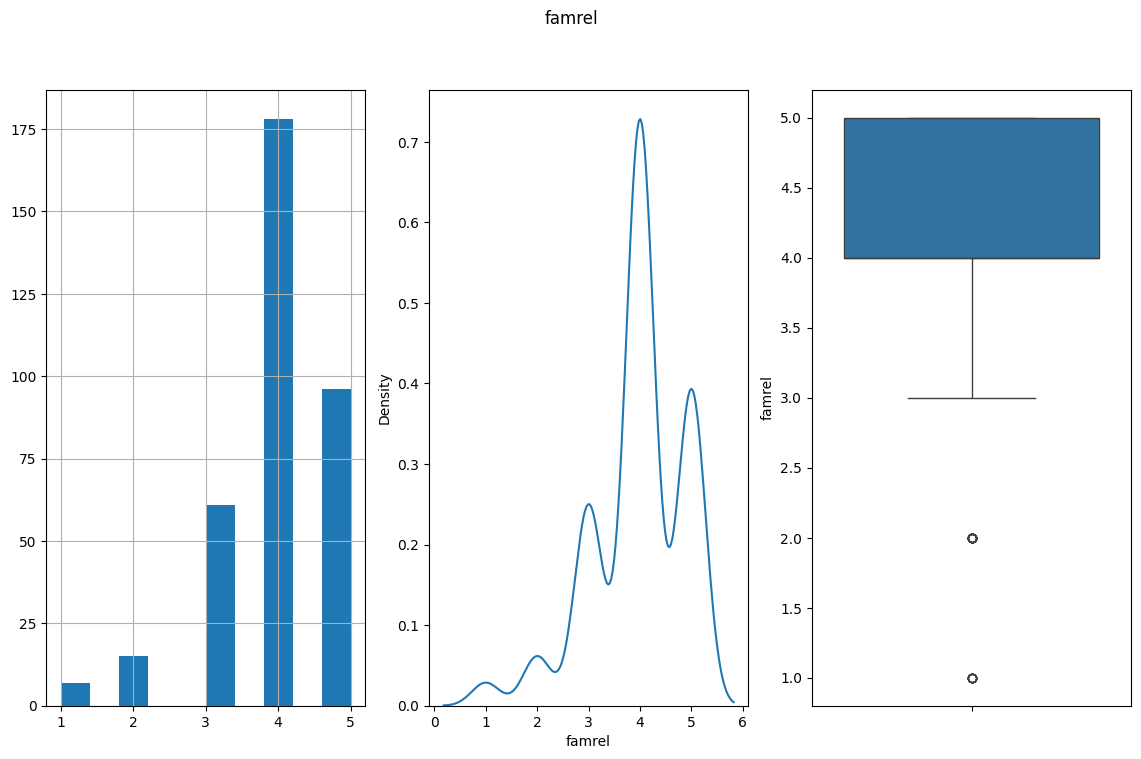

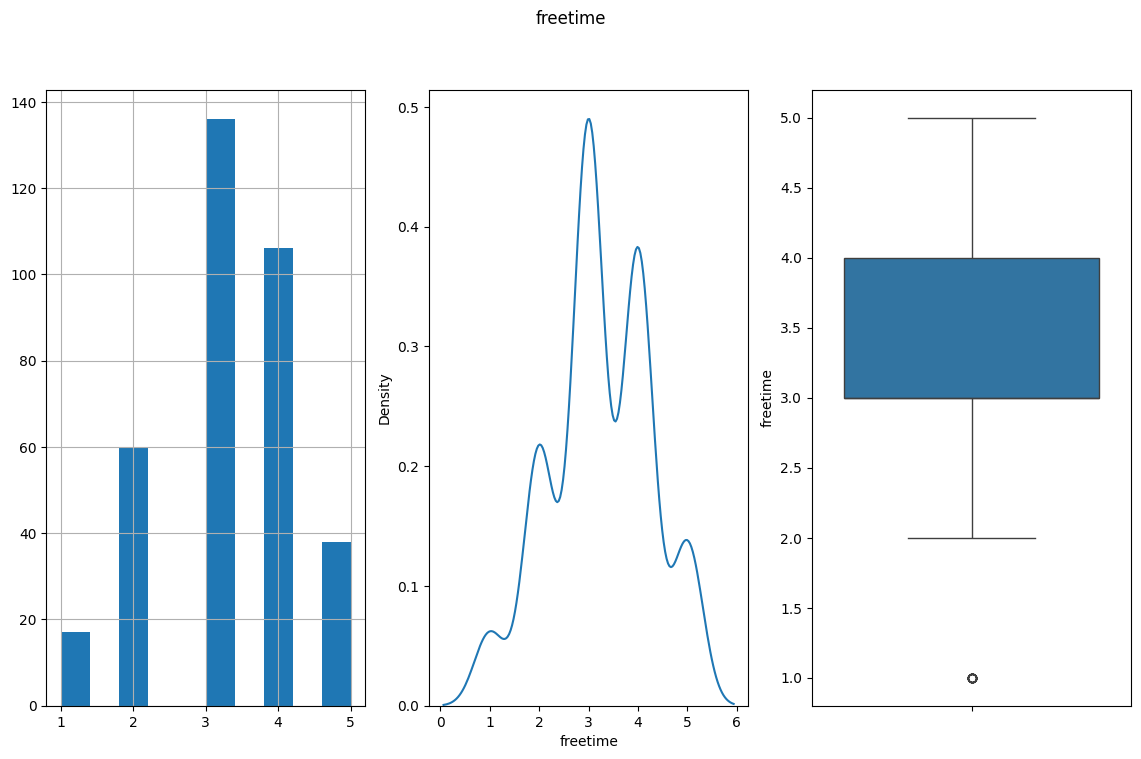

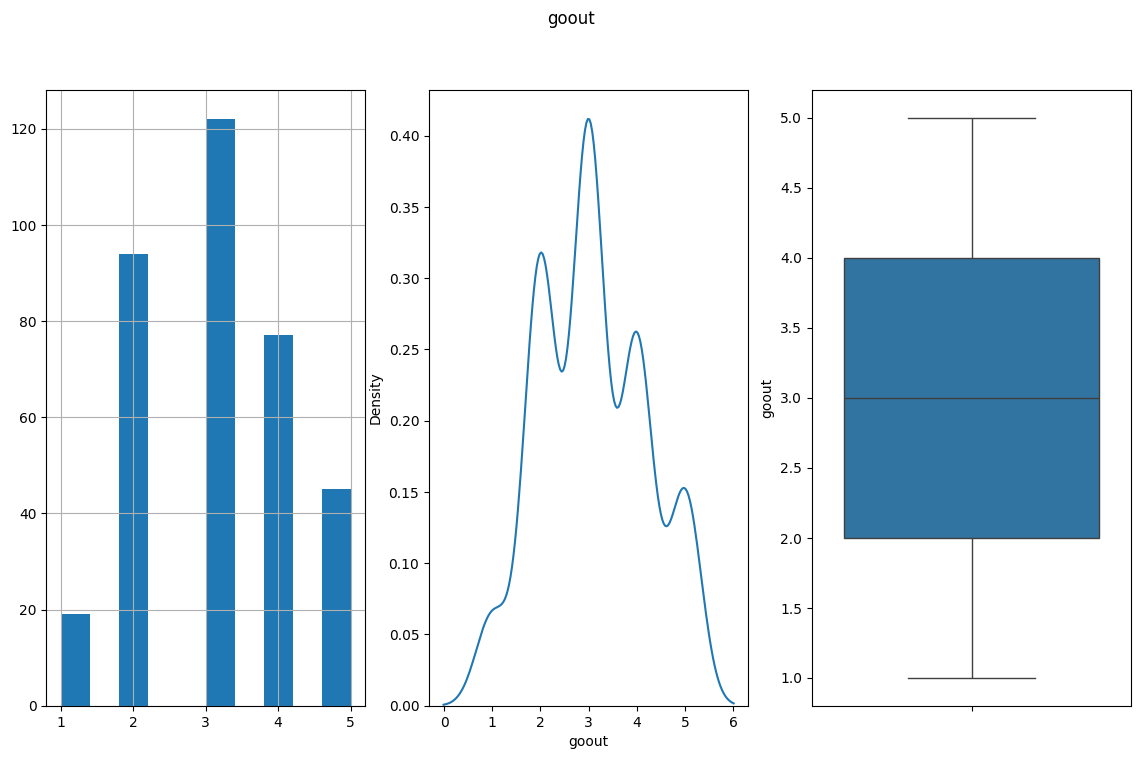

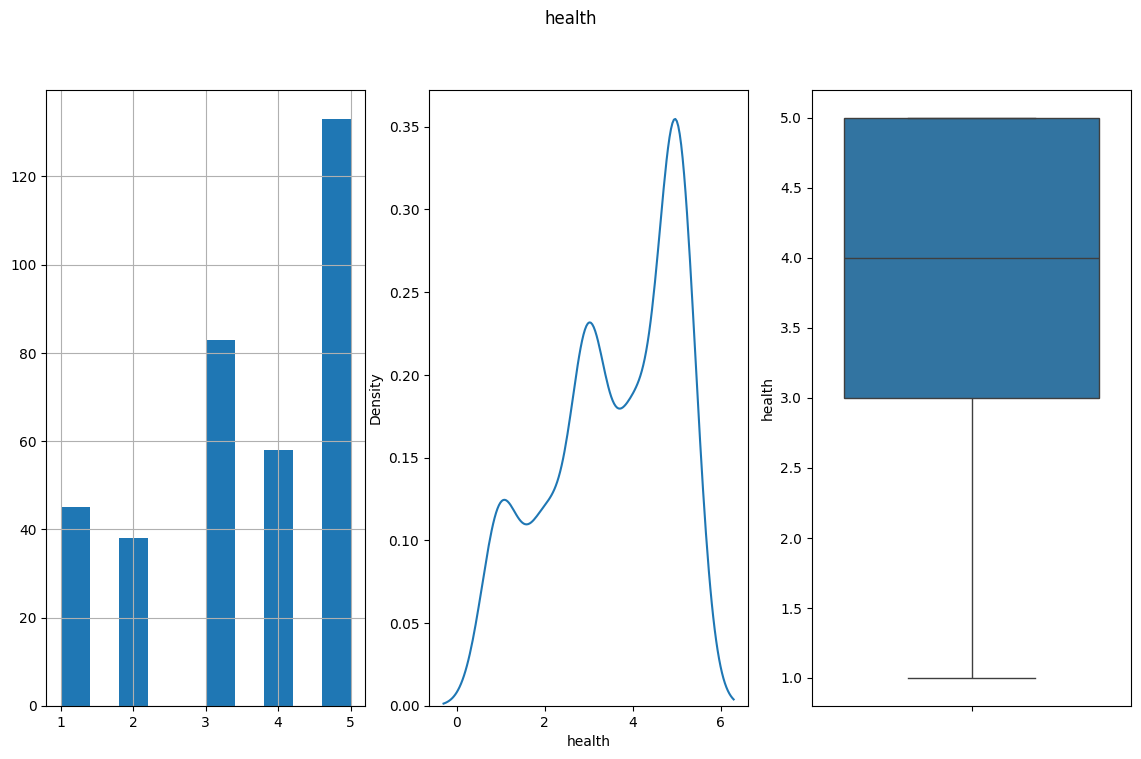

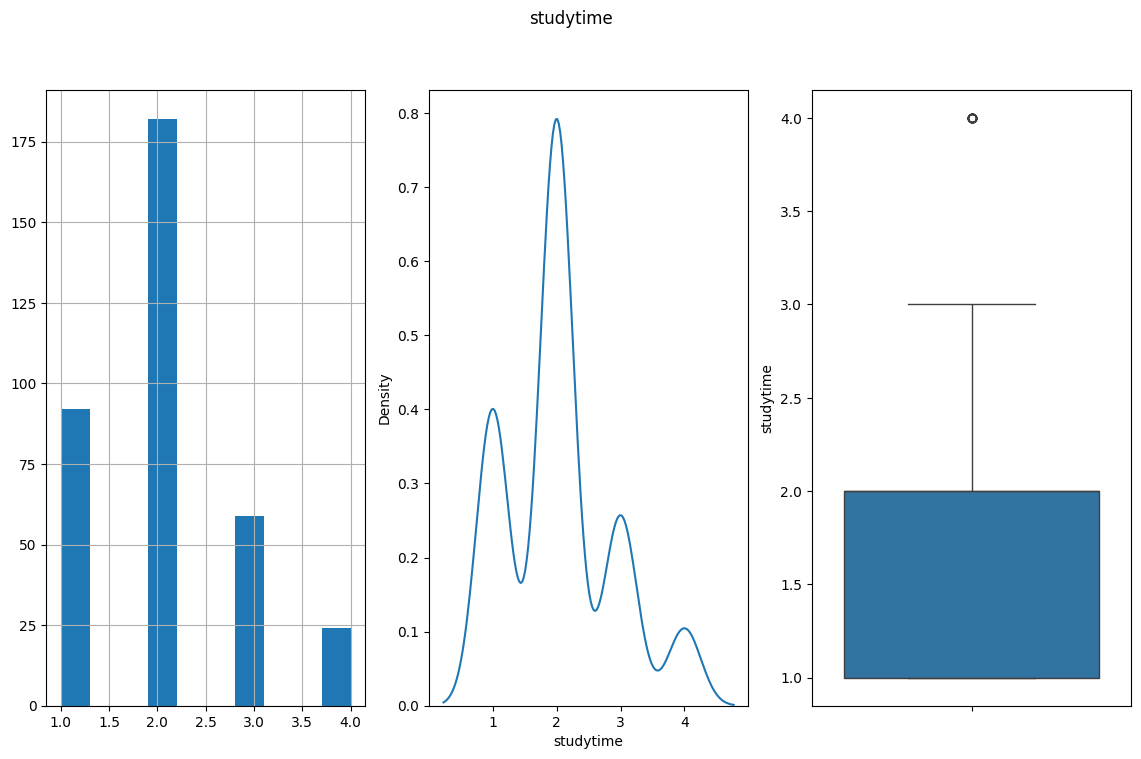

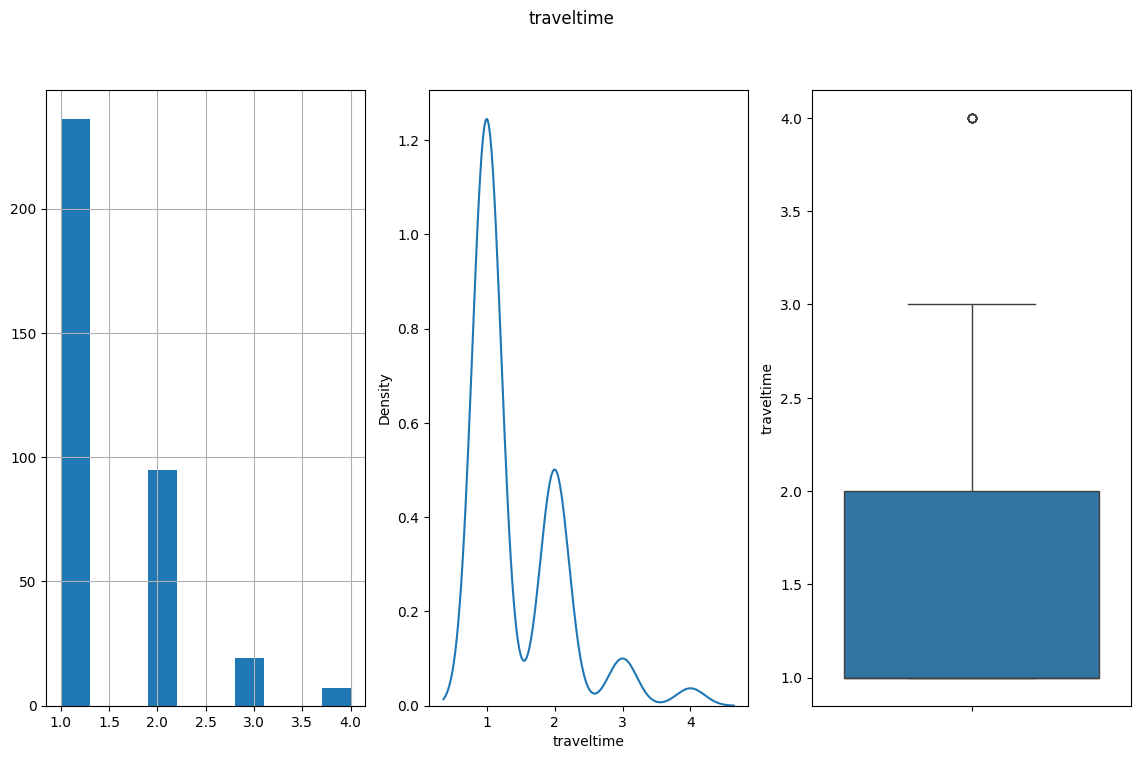

In [ ]:
# Displaying histogram, kernel density plot and boxplot for each numerical feature

for col in quantitative_features:
    plt.figure(figsize = (14,8))
    plt.suptitle(col)
    plt.subplot(1,3,1)
    df[col].hist()
    plt.subplot(1,3,2)
    sns.kdeplot(df[col])
    plt.subplot(1,3,3)
    sns.boxplot(y = col, data = df)

In [ ]:
target = "FinalGrade"

corr = df[quantitative_features].corr(method="pearson")[target].sort_values(ascending=False)

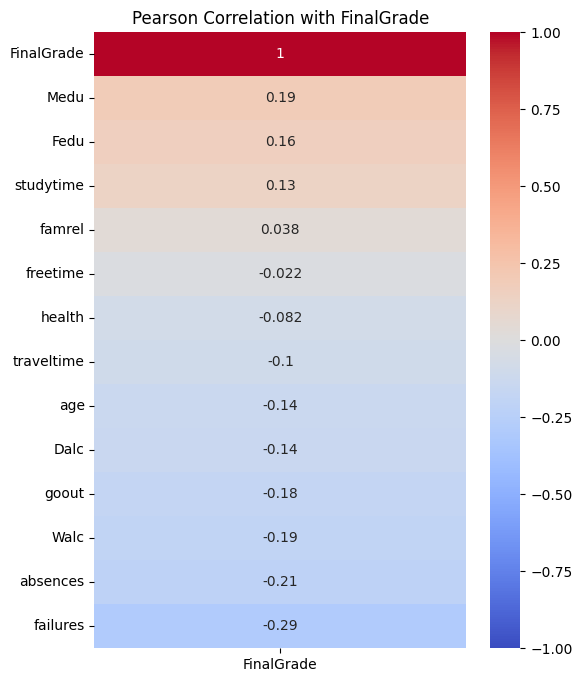

In [ ]:
plt.figure(figsize=(6, 8))
sns.heatmap(
    corr.to_frame(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title(f"Pearson Correlation with {target}")
plt.show()

## **Key insights**

- **Strongest positive correlations**: Mother's education (Medu: 0.19) and father's education (Fedu: 0.16) have the most positive impact, followed by study time (0.13), suggesting parental education and dedicated study habits boost performance.
- **Weak positives**: Family relations (famrel: 0.038) show minor positive ties.
- **Negative correlations**: Past failures (-0.29) and absences (-0.21) have the strongest negative links, implying they significantly hinder grades. Alcohol consumption (Walc: -0.19, Dalc: -0.14) and socializing (goout: -0.18) also correlate negatively, while age (-0.14), travel time (-0.1), health (-0.082), and free time (-0.022) show weaker drags.


In [ ]:
for val in qualitative_features:
  print(df[val].nunique())

2
2
2
2
5
5
4
3
2
2
2
2
2
2
2
2


In [ ]:
def is_normal_distribution(*groups, alpha=0.05):
    """
    Returns a dictionary of normality tests for each group.

    Parameters:
    - *groups: one or more pandas Series / array-like
    - alpha: significance level (default 0.05)

    Returns:
    - dict: {group_index: True/False}
    """

    results = {}

    for i, g in enumerate(groups, start=1):
        data = g.dropna()
        stat, p_value = stats.shapiro(data)
        results[i] = p_value > alpha  # True if normal

    return results

In [ ]:
def is_all_normal(*groups, alpha=0.05):
    return all(is_normal_distribution(*groups, alpha=alpha).values())

In [ ]:
def has_equal_variance(*groups, alpha=0.05):
    """
    Returns True if all groups have equal variances
    using Levene's test.

    Parameters:
    - *groups: two or more numerical samples
    - alpha: significance level (default 0.05)
    """

    if len(groups) < 2:
        raise ValueError("Levene test requires at least two groups.")

    # Remove missing values
    groups = [g.dropna() for g in groups]

    stat, p_value = stats.levene(*groups, center="median")

    return p_value > alpha

In [ ]:
def is_significant_anova(*groups, alpha=0.05, eq_var):
    """
    Returns True if there is a statistically significant difference
    between group means (one-way ANOVA).

    H0: all group means are equal
    """

    if len(groups) < 2:
        raise ValueError("ANOVA requires at least two groups.")

    groups = [g.dropna() for g in groups]

    f_stat, p_value = stats.f_oneway(*groups, equal_var= eq_var)

    return p_value < alpha

In [ ]:
def is_significant_ttest(data1, data2, eq_var, alpha=0.05):
    """
    Returns True if the two group means are significantly different
    (independent samples t-test).

    H0: both means are equal
    """

    data1 = data1.dropna()
    data2 = data2.dropna()

    t_stat, p_value = stats.ttest_ind(data1, data2, equal_var= eq_var)

    return p_value < alpha

In [ ]:
def is_significant_mannwhitney(data1, data2, alpha=0.05):
    """
    Returns True if the two groups are significantly different
    (Mann–Whitney U test).

    H0: both distributions are equal
    """

    data1 = data1.dropna()
    data2 = data2.dropna()

    stat, p_value = stats.mannwhitneyu(
        data1,
        data2,
        alternative="two-sided"
    )

    return p_value < alpha

In [ ]:
def is_significant_kruskal(*groups, alpha=0.05):
    """
    Returns True if at least one group differs significantly
    (Kruskal–Wallis test).

    H0: all group distributions are equal
    """

    if len(groups) < 2:
        raise ValueError("Kruskal–Wallis requires at least two groups.")

    groups = [g.dropna() for g in groups]

    stat, p_value = stats.kruskal(*groups)

    return p_value < alpha

In [ ]:
def split_groups(df, group_col, value_col):
    """
    Returns a dictionary of groups.

    Example:
    {
        'M': array([...]),
        'F': array([...])
    }
    """

    groups = {
        name: group[value_col].dropna()
        for name, group in df.groupby(group_col)
    }

    return groups

In [ ]:
len(split_groups(df, "sex", "FinalGrade"))

2

In [ ]:
important_qual_feat = []

In [ ]:
for col in qualitative_features:
  groups = split_groups(df, col, "FinalGrade")
  if is_all_normal(*groups.values()):
    if len(groups) > 2:
      if is_significant_anova(*groups.values(), eq_var= has_equal_variance(*groups.values())):
        important_qual_feat.append(col)
    else:
      if is_significant_ttest(*groups.values(), eq_var= has_equal_variance(*groups.values())):
        important_qual_feat.append(col)
  else:
    if len(groups) > 2:
      if is_significant_kruskal(*groups.values()):
        important_qual_feat.append(col)
    else:
      if is_significant_mannwhitney(*groups.values()):
        important_qual_feat.append(col)

In [ ]:
important_qual_feat

['address', 'Mjob', 'schoolsup', 'higher', 'internet']

## **Key insights**

1. **`address`** → Students’ home location (urban/rural) seems to influence grades.
2. **`Mjob`** → Mother’s job type has a measurable effect on student performance.
3. **`schoolsup`** → Extra educational support at school is associated with grade differences.
4. **`higher`** → Desire to pursue higher education impacts grades.
5. **`internet`** → Access to internet at home correlates with better performance.



Out of all 17 qualitative features, only **5 show a significant effect** on `FinalGrade`.
These features could be **important predictors** for modeling or deeper analysis.

# **Feature engineering**

In [ ]:
label_encoders = {}
print("Empty dictionary 'label_encoders' created.")

Empty dictionary 'label_encoders' created.


In [ ]:
df_encoded = df.copy()

In [ ]:
for col in qualitative_features:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

print("Qualitative features encoded and stored.")

Qualitative features encoded and stored.


In [82]:
df_encoded

,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,FinalGrade
0,0,18,1,0,0,4,4,0,4,0,1,2,2,0,1,0,0,0,1,1,0,0,4,3,4,1,1,3,6,6
1,0,17,1,0,1,1,1,0,2,0,0,1,2,0,0,1,0,0,0,1,1,0,5,3,3,1,1,3,4,6
2,0,15,1,1,1,1,1,0,2,2,1,1,2,3,1,0,1,0,1,1,1,0,4,3,2,2,3,3,10,10
3,0,15,1,0,1,4,2,1,3,1,1,1,3,0,0,1,1,1,1,1,1,1,3,2,2,1,1,5,2,15
4,0,16,1,0,1,3,3,2,2,1,0,1,2,0,0,1,1,0,1,1,0,0,4,3,2,1,2,5,4,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,1,20,1,1,0,2,2,3,3,0,2,1,2,2,0,1,1,0,1,1,0,0,5,5,4,4,5,4,11,9
353,1,17,1,1,1,3,1,3,3,0,1,2,1,0,0,0,0,0,0,1,1,0,2,4,5,3,4,2,3,16
354,1,21,0,0,1,1,1,2,2,0,2,1,1,3,0,0,0,0,0,1,0,0,5,5,3,3,3,3,3,7
355,1,18,0,1,1,3,2,3,2,0,1,3,1,0,0,0,0,0,0,1,1,0,4,4,1,3,4,5,0,10


In [84]:
df_encoded.to_csv("df_transformed.csv", index = False)